In [ ]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from jaxopt import AndersonAcceleration
import pickle
import os
import optax
from scipy import stats
from scipy.optimize import curve_fit
import pandas as pd
import seaborn as sns
from tqdm import trange
from itertools import product
import openpyxl
from sklearn.cluster import KMeans
from scipy.optimize import linear_sum_assignment




## 1. Naka–Rushton 

Fixing Hill exponents from Elisa

In [ ]:
# Naka-Rushton function

def nr(x, n):
    """Naka-Rushton activation function"""
    x = jnp.maximum(x, 0.0)
    return jnp.power(x, n) / (jnp.power(x, n) + 1)

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


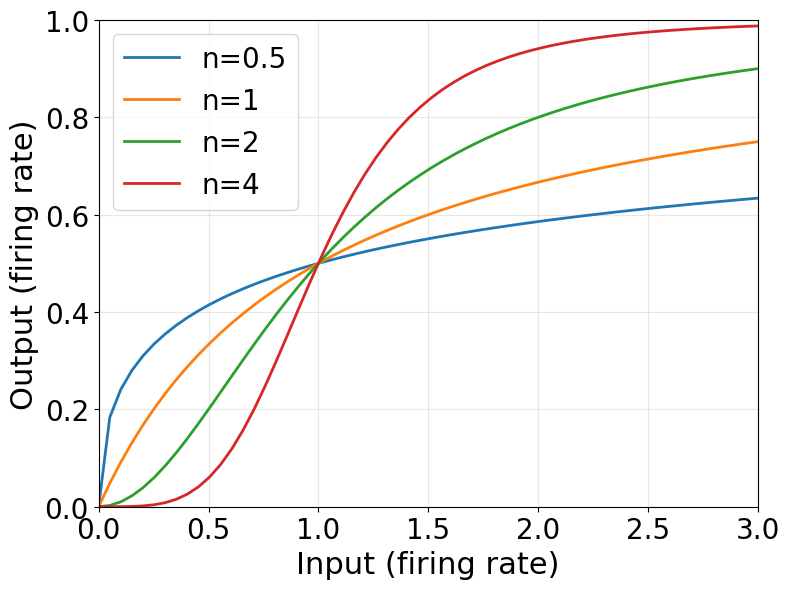

In [ ]:
# Visualise the Naka-Rushton function
x_vals = jnp.linspace(0, 5, 100)
n_values = [0.5, 1, 2, 4]

plt.figure(figsize=(8, 6))
for n in n_values:
    y_vals = nr(x_vals, n=n)
    plt.plot(x_vals, y_vals, label=f'n={n}', linewidth=2)

plt.xlabel('Input (firing rate)', fontsize=22)
plt.ylabel('Output (firing rate)', fontsize=22)
plt.grid(True, alpha=0.3)
plt.xlim(0, 3)
plt.ylim(0, 1)
plt.tick_params(axis='both', direction='out', labelsize=20)
plt.legend(fontsize=20)
plt.tight_layout()
plt.savefig(f'Figures_final/naka_rushton_og.eps')
plt.show()

In [ ]:
n_r = 1.850
n_g = 1.868
n_b = 0.642
n_y = 1.562

## 2. Symmetric weight



In [ ]:

def unpack_theta(theta, m):
    w_osn_r = jnp.array([theta[0], theta[0]])
    w_osn_b = jnp.array([theta[1], theta[1]])
    w_osn_g = jnp.array([theta[2], theta[2]])
    w_osn_y = jnp.array([theta[3], theta[3]])
    w_b_r = jnp.array([theta[4], theta[4]])
    w_b_g = jnp.array([theta[5], theta[5]])
    w_b_y = jnp.array([theta[6], theta[6]])
    w_r_y = jnp.array([theta[7], theta[7]])
    w_r_g = jnp.array([theta[8], theta[8]])
    alpha = jnp.array([theta[9], theta[9]])
    # Build 2x2 matrices so all elements are same type (avoids JAX shape error)
    zero = jnp.asarray(0.0)
    wr = jnp.asarray(theta[10])
    wy = jnp.asarray(theta[11])
    W_g_r = jnp.stack([jnp.stack([zero, wr]), jnp.stack([wr, zero])])
    W_g_y = jnp.stack([jnp.stack([zero, wy]), jnp.stack([wy, zero])])
    y_max_g = theta[12]
    return w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y, y_max_g


# Fixed-point function for green neurons with different n values
def mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g, y_max_g):
    """Fixed point equation for green neurons with different n values"""
    b_input = w_osn_b * alpha * x
    b_out = nr(b_input, n=n_b)

    r_input = w_osn_r * alpha * x - w_b_r * b_out - W_g_r @ g
    r_out = nr(r_input, n=n_r)

    g_input = w_osn_g * alpha * x - w_b_g * b_out + w_r_g * r_out
    g_new = nr(g_input, n=n_g) * y_max_g

    return g_new

# Solve fixed point via Anderson Acceleration with different n values
def solve_fixed_point(theta, x, m, n_r, n_b, n_g):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y, y_max_g = unpack_theta(theta, m)
    g0 = jnp.zeros(m)

    # Pass y_max_g as explicit arg so JAX can differentiate w.r.t. it (closed-over values break custom_vjp)
    def fixed_point_with_y_max(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, y_max_g):
        return mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g, y_max_g)

    aa = AndersonAcceleration(fixed_point_with_y_max, history_size=5, tol=1e-10, maxiter=50)
    solution = aa.run(g0, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, y_max_g)
    return solution.params

# Compute mitral output with different n values
def mitral_output(theta, x, m, n_r, n_b, n_g, n_y):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y, y_max_g = unpack_theta(theta, m)

    g = solve_fixed_point(theta, x, m, n_r, n_b, n_g)
    b = nr(w_osn_b * alpha * x, n=n_b)
    r = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g, n=n_r)
    y = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g + w_r_y * r, n=n_y)

    return r, g, b, y

## 3. Random initialisations and Adam optimisation to hit output targets

- draw many initial `theta`
- minimise a squared-error loss on target firing rates
- keep converged solutions

In [ ]:
# set up optimisation problem
m = 2  # number of mitral neurons
n_var = 4  # r, g, b, y
n = n_var * m  # total state length
x = jnp.ones(m)  # input odour signal

# Naka-Rushton n values for each neuron type
n_r = 1.850
n_g = 1.868
n_b = 0.642
n_y = 1.562

# target firing rates (all neurons should fire around 0.5)
y_target = jnp.array([0.5, 0.5])  # mitral cell output
g_target = jnp.array([0.5, 0.5])  # green neurons
b_target = jnp.array([0.5, 0.5])  # blue neurons
r_target = jnp.array([0.5, 0.5])  # red neurons

# number of parameters in the model
# parameters: w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g,
#            alpha, W_g_r, W_g_y, y_max_g
no_params = 13  # total number of parameters

print(f"Setup:")
print(f"  - Number of mitral neurons (channels): {m}")
print(f"  - Number of parameters: {no_params}")
print(f"  - Target firing rates: {np.array(y_target)}")
print(f"  - Input signal: {np.array(x)}")
print(f"  - N values: n_r={n_r}, n_b={n_b}, n_g={n_g}, n_y={n_y}")

## 4. Load params, test stability 



In [ ]:
# Load theta_opt from pickle file
theta_opt_file = 'Theta_opt/theta_opt_xx_zz.pkl'
with open(theta_opt_file, 'rb') as f:
    theta_opt = pickle.load(f)

theta_opt = np.array(theta_opt)
initial_count = theta_opt.shape[0]  # Store initial count 
print(f"Loaded theta_opt shape: {theta_opt.shape}")
print(f"Number of samples: {theta_opt.shape[0]}")
print(f"Number of parameters per sample: {theta_opt.shape[1]}")

All stable, therefore can just use theta_opt

## 5. Hessian 


Processing 570 samples...
  Sample 1/570...
  Sample 101/570...
  Sample 201/570...
  Sample 301/570...
  Sample 401/570...
  Sample 501/570...
Completed processing 570 samples


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


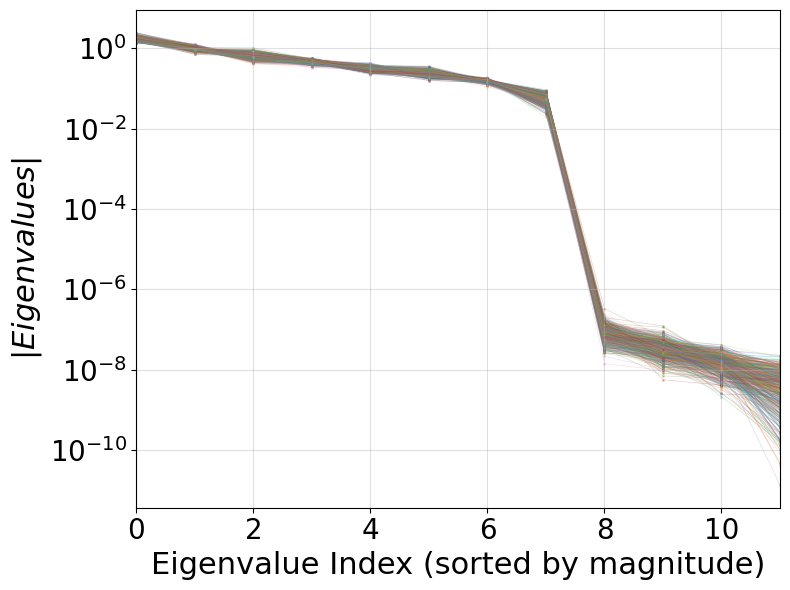

In [ ]:
@jax.jit
def y_output_sum(theta):
    """Compute output y as a function of parameters"""
    r, g, b, y = mitral_output(theta, x, m, n_r, n_b, n_g, n_y)
    return jnp.sum(y)

grad = jax.jit(jax.grad(y_output_sum))
hessian = jax.jit(jax.jacrev(grad))

theta_samples = theta_opt
near_zero_threshold = 1e-5

print(f"Processing {theta_samples.shape[0]} samples...")
n_samples, n_params = theta_samples.shape[0], theta_samples.shape[1]
all_eigenvalues = np.zeros((n_samples, n_params))
all_eigenvectors = np.zeros((n_samples, n_params, n_params))

# Process all samples
for i in range(n_samples):
    if i % 100 == 0:
        print(f"  Sample {i+1}/{n_samples}...")

    theta_star = jnp.array(theta_samples[i, :])
    H = jnp.squeeze(hessian(theta_star))

    # Compute and sort eigenvalues in one step
    eigenvalues_H = np.array(jnp.linalg.eigh(H).eigenvalues)
    eigenvectors_H = np.array(jnp.linalg.eigh(H).eigenvectors)
    all_eigenvalues[i, :] = np.abs(eigenvalues_H[np.argsort(np.abs(eigenvalues_H))[::-1]])
    all_eigenvectors[i, :, :] = eigenvectors_H[:, np.argsort(np.abs(eigenvalues_H))[::-1]]

print(f"Completed processing {n_samples} samples")

# Visualise
fig, ax = plt.subplots(figsize=(8, 6))
n_params = all_eigenvalues.shape[1]

# Plot individual samples (one colour per sample)
x_idx = np.arange(n_params)
for i in range(n_samples):
    ax.semilogy(x_idx, all_eigenvalues[i, :], 'o-', ms=1, lw=0.4, alpha=0.3, zorder=1)

# Plot statistics
ax.set_xlabel('Eigenvalue Index (sorted by magnitude)', fontsize=22)
ax.set_ylabel('$|Eigenvalues|$', fontsize=22)
ax.set_xlim(0, n_params-1)
ax.tick_params(axis='both', labelsize=20, direction='out')
ax.grid(True, alpha=0.4)
plt.tight_layout()
plt.savefig('Figures_final/hessian_eigenvalues.eps')
plt.show()

In [ ]:

threshold = 1e-5  # Threshold for near-zero eigenvalues

def get_subspace2_eigenvectors(sample_idx, all_eigenvalues, all_eigenvectors, threshold=1e-5):

    eigenvalues = all_eigenvalues[sample_idx, :]
    eigenvectors = all_eigenvectors[sample_idx, :, :]  # Shape: (n_params, n_params)

    # Find indices where eigenvalues < threshold
    near_zero_mask = eigenvalues < threshold
    n_near_zero = np.sum(near_zero_mask)

    # Extract corresponding eigenvectors (each column is an eigenvector)
    eigenvectors_subspace2 = eigenvectors[:, near_zero_mask].T  # Shape: (n_near_zero, n_params)

    return eigenvectors_subspace2

In [ ]:

# Concatenate all near-zero eigenvectors from all samples
all_eigenvectors_subspace2 = []
for i in range(n_samples):
    vecs = get_subspace2_eigenvectors(i, all_eigenvalues, all_eigenvectors, threshold=threshold)
    all_eigenvectors_subspace2.append(vecs)
# Stack all (variable-sized, so use vstack)
eigenvectors_concat = np.vstack(all_eigenvectors_subspace2)  # Shape: (total_vectors, n_params)

# Perform SVD on concatenated eigenvectors
U, S, Vt = np.linalg.svd(eigenvectors_concat, full_matrices=False)

# Plot singular values vs index
plt.figure(figsize=(8, 6))
plt.plot(np.arange(0, len(S)), S, 'o-', color='crimson', lw=2, ms=6)
plt.xlabel('Singular Value Index', fontsize=22)
plt.ylabel('Singular Value ', fontsize=22)
plt.xlim(-0.2, len(S)-1+0.2)
plt.grid(True, alpha=0.7)
plt.tick_params(axis='both', labelsize=20)
plt.tight_layout()
plt.savefig('Figures_final/svd_singular_values.eps')
plt.show()

In [ ]:
Vt[:4].shape # orthonormal rows
Vt[:4].T.shape # orthonormal columns

## 6. Many Q tilde initialisations (1 op)



In [ ]:
# Vectorized version of sparse_rotation for parallelization
def sparse_rotation_vectorized(U, keys, use_scheduler=True, scheduler_type='plateau', n_iterations=10000):

    batch_size = keys.shape[0]
    k = U.shape[1]
    n = U.shape[0]
    
    def loss(qtilde):
        """Loss function: mean of absolute values of rotated u"""
        q, _ = jnp.linalg.qr(qtilde)
        u_rotated = U @ q
        return jnp.mean(jnp.abs(u_rotated))
    
    def optimize_single(key):
        """Optimize for a single initialization"""
        key, subkey = jax.random.split(key)
        qtilde = jax.random.normal(subkey, (k, k))
        
        # Set up optimizer
        if use_scheduler:
            if scheduler_type == 'cosine':
                schedule = optax.cosine_decay_schedule(
                    init_value=0.01,
                    decay_steps=n_iterations,
                    alpha=0.1
                )
                optimizer = optax.chain(
                    optax.scale_by_adam(eps=1e-4),
                    optax.scale_by_schedule(schedule)
                )
            elif scheduler_type == 'step':
                schedule = optax.piecewise_constant_schedule(
                    init_value=0.01,
                    boundaries_and_scales={5000: 0.5, 8000: 0.5}
                )
                optimizer = optax.chain(
                    optax.scale_by_adam(eps=1e-4),
                    optax.scale_by_schedule(schedule)
                )
            else:  # 'plateau' or default
                # For plateau, use fixed LR of 0.01
                # The original plateau scheduler keeps LR at 0.01 for most iterations
                # (reduces only when loss plateaus, typically after 3000+ iterations)
                # Using fixed 0.01 should give similar results since most optimization
                # happens at this LR anyway
                optimizer = optax.adam(learning_rate=0.01, eps=1e-4)
        else:
            optimizer = optax.adam(learning_rate=0.01, eps=1e-4)
        
        opt_state = optimizer.init(qtilde)
        loss_value_and_grad = jax.value_and_grad(loss)
        
        # Optimization loop - use scan for efficiency
        def step(carry, i):
            qtilde, opt_state = carry
            loss_value, grads = loss_value_and_grad(qtilde)
            updates, opt_state = optimizer.update(grads, opt_state)
            qtilde = optax.apply_updates(qtilde, updates)
            return (qtilde, opt_state), loss_value
        
        (qtilde_final, _), loss_history = jax.lax.scan(
            step, (qtilde, opt_state), jnp.arange(n_iterations)
        )
        
        # Get final Q
        q_opt, _ = jnp.linalg.qr(qtilde_final)
        U_sparse = U @ q_opt
        
        return U_sparse, loss_history[-1]
    
    # Vectorize over keys using vmap and JIT compile for speed
    optimize_batch = jax.jit(jax.vmap(optimize_single))
    
    # Process all keys in parallel (JIT compilation happens on first call)
    U_sparse_batch, loss_values = optimize_batch(keys)
    
    return U_sparse_batch, loss_values

In [ ]:
# PARALLELIZED VERSION - Use this instead
n_key = 1000
batch_size = 100  # Process in batches to manage memory

n, k = Vt[:4].T.shape

# Configuration
config = {'use_scheduler': True, 'scheduler_type': 'plateau', 'label': 'Plateau Scheduler'}

# Generate all random keys upfront
print(f"Generating {n_key} random keys...")
keys = jax.random.split(jax.random.PRNGKey(0), n_key)

# Process in batches for memory efficiency
print(f"Processing {n_key} initializations in batches of {batch_size}...")
U_sparse_all = []
loss_values_all = []

for batch_start in trange(0, n_key, batch_size):
    batch_end = min(batch_start + batch_size, n_key)
    batch_keys = keys[batch_start:batch_end]
    
    # Process batch in parallel using JAX vmap
    U_sparse_batch, loss_batch = sparse_rotation_vectorized(
        Vt[:4].T,
        batch_keys,
        use_scheduler=config['use_scheduler'],
        scheduler_type=config['scheduler_type'] if config['use_scheduler'] else None,
        n_iterations=10000
    )
    
    U_sparse_all.append(np.array(U_sparse_batch))
    loss_values_all.append(np.array(loss_batch))

# Concatenate results
U_sparse_coll = np.concatenate(U_sparse_all, axis=0)
loss_value_coll = np.concatenate(loss_values_all, axis=0)

print(f"\nCompleted! Processed {n_key} initializations.")
print(f"Loss range: [{loss_value_coll.min():.6f}, {loss_value_coll.max():.6f}]")
print(f"Mean loss: {loss_value_coll.mean():.6f}")

np.savez_compressed('U_sparse_save.npz', U_sparse_coll=U_sparse_coll, loss_value_coll=loss_value_coll)

Generating 1000 random keys...
Processing 1000 initializations in batches of 100...


100%|██████████| 10/10 [00:13<00:00,  1.32s/it]


Completed! Processed 1000 initializations.
Loss range: [0.130761, 0.162482]
Mean loss: 0.132788


In [ ]:
U_sparse_save = np.load('U_sparse_save.npz')['U_sparse_coll']
loss_value_coll = np.load('U_sparse_save.npz')['loss_value_coll']
U_sparse_save.shape
#loss_value_coll.shape

(1000, 13, 4)

In [ ]:
# SVD basis (before sparse rotation): Vt[:4].T is the input to sparse_rotation_vectorized
U_svd = Vt[:4].T  # shape (n_params, 4); requires Hessian + SVD cells above

param_labels = [
    'w_osn_r', 'w_osn_b', 'w_osn_g', 'w_osn_y',
    'w_b_r', 'w_b_g', 'w_b_y',
    'w_r_y', 'w_r_g', r'$\alpha$', 'W_g_r', 'W_g_y',
    'y_max_g',
]
x_labels = []
for lbl in param_labels:
    if lbl.count('_') >= 2:
        base, suffix = lbl.rsplit('_', 1)
        x_labels.append(f'{base},{suffix}')
    else:
        x_labels.append(lbl)

n_components = U_svd.shape[1]
x_params = np.arange(U_svd.shape[0])

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for i in range(n_components):
    axes[i].plot(x_params, U_svd[:, i], 'o-', color='tab:blue', lw=4, ms=7, alpha=0.8)
    axes[i].set_xticks(x_params)
    if i >= 2:
        axes[i].set_xticklabels(x_labels, rotation=45, ha='right', fontsize=20)
    else:
        axes[i].tick_params(labelbottom=False)
    axes[i].tick_params(axis='y', labelsize=20)
    axes[i].grid(True, alpha=0.3)
    axes[i].set_title(f'SVD basis vector {i + 1}', fontsize=22, fontweight='bold')

plt.tight_layout()
plt.show()

In [ ]:
# Sparse basis from the first Q initialisation (keys[0] in the 1000-run batch)
U_sparse_first = U_sparse_save[1]  # same as sparse_rotation_vectorized(..., keys[:1])[0]
loss_first = float(loss_value_coll[0])

param_labels = [
    'w_osn_r', 'w_osn_b', 'w_osn_g', 'w_osn_y',
    'w_b_r', 'w_b_g', 'w_b_y',
    'w_r_y', 'w_r_g', r'$\alpha$', 'W_g_r', 'W_g_y',
    'y_max_g',
]

n_components = U_sparse_first.shape[1]
x_params = np.arange(U_sparse_first.shape[0])

fig, axes = plt.subplots(1, n_components, figsize=(3.5 * n_components, 5), sharex=True, sharey=True)
if n_components == 1:
    axes = [axes]

for col in range(n_components):
    axes[col].plot(x_params, U_sparse_first[:, col], 'o-', color='C1', lw=2, ms=6)
    axes[col].set_xticks(x_params)
    axes[col].set_xticklabels(param_labels, rotation=45, ha='right', fontsize=9)
    axes[col].grid(True, alpha=0.3)
    axes[col].set_title(f'Sparse basis vector {col + 1}', fontsize=12)
    if col == 0:
        axes[col].set_ylabel('Component value', fontsize=11)


plt.tight_layout()
plt.show()

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


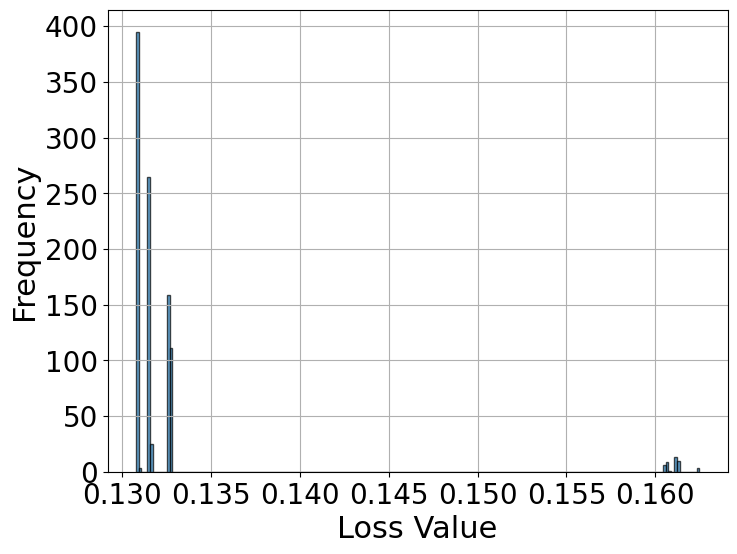

In [ ]:
# plot histogram of loss values

plt.figure(figsize=(8,6))
plt.hist(loss_value_coll, bins=200, alpha=0.7, edgecolor='black')
plt.xlabel('Loss Value', fontsize=22)
plt.ylabel('Frequency', fontsize=22)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.grid()
plt.savefig('Figures_final/sparse_loss_histogram.eps')
plt.show()


In [ ]:
# Isolate lowest-loss cluster and check subspace matching
# Split all 1000 solutions into 3 broad clusters

kmeans3 = KMeans(n_clusters=2, random_state=0, n_init=10)
labels3 = kmeans3.fit_predict(loss_value_coll.reshape(-1, 1))
centroids3 = kmeans3.cluster_centers_.flatten()
best_cluster_id = np.argmin(centroids3)

best_mask_broad = labels3 == best_cluster_id
loss_broad = loss_value_coll[best_mask_broad]

print(f"3-cluster centroids (sorted): {np.sort(centroids3)}")
print(f"Broad lowest cluster: {best_mask_broad.sum()} solutions, "
      f"loss ∈ [{loss_broad.min():.6f}, {loss_broad.max():.6f}]")


3-cluster centroids (sorted): [0.13154805 0.16107477]
Broad lowest cluster: 958 solutions, loss ∈ [0.130761, 0.132808]


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


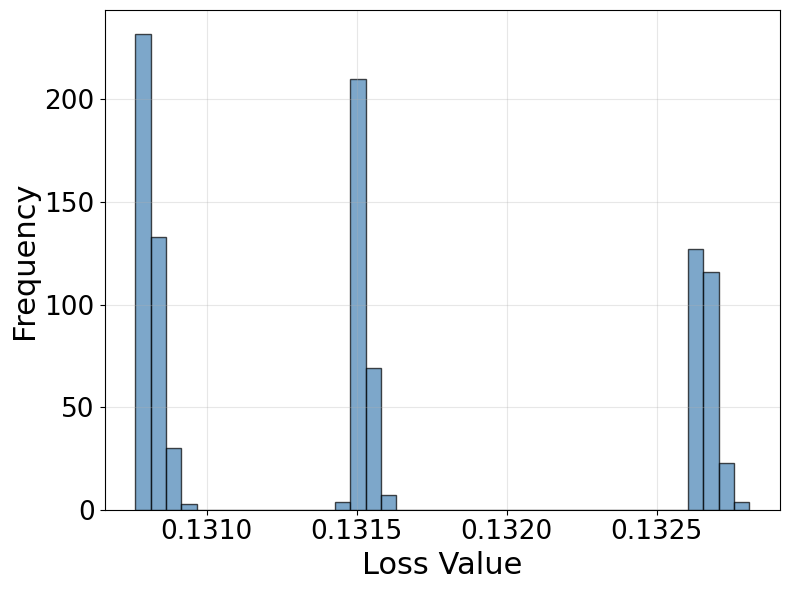

In [ ]:
# Zoom into the lowest cluster (2 sub-peaks)
fig, ax = plt.subplots(figsize=(8, 6))

# Zoomed histogram of lowest broad cluster
ax.hist(loss_broad, bins=40, alpha=0.7, edgecolor='black', color='steelblue')
ax.set_xlabel('Loss Value', fontsize=22)
ax.set_ylabel('Frequency', fontsize=22)
ax.tick_params(axis='both', labelsize=19)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('Figures_final/sparse_loss_histogram_lowest_peak.eps')
plt.show()

In [ ]:
U_sparse_save.shape

(1000, 13, 4)

In [ ]:
# Use entire lowest broad cluster as U_best (no sub-clustering)
broad_indices = np.where(best_mask_broad)[0]
sub_best_indices = broad_indices  # global θ* indices (for downstream cells)

U_best = U_sparse_save[broad_indices]          # shape: (n_best, 13, 4)
loss_best = loss_value_coll[broad_indices]

print(f"\nLowest broad cluster: {U_best.shape[0]} solutions, "
      f"loss ∈ [{loss_best.min():.6f}, {loss_best.max():.6f}]")


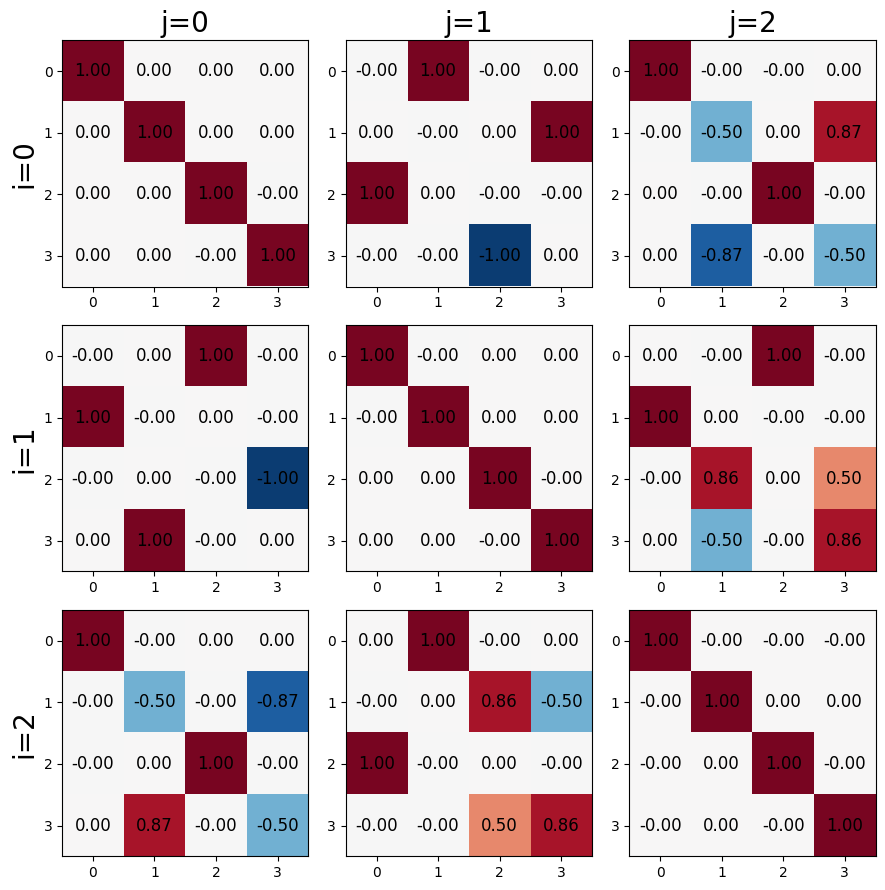

In [ ]:
# Pairwise dot products  U_i^T @ U_j  for the lowest sub-peak
n_best = U_best.shape[0]
n_show = min(n_best, 3)

fig, axes_grid = plt.subplots(n_show, n_show, figsize=(3 * n_show, 3 * n_show))
for i in range(n_show):
    for j in range(n_show):
        P = U_best[i].T @ U_best[j]   # (4, 4)
        axes_grid[i, j].imshow(P, cmap='RdBu_r', vmin=-1.05, vmax=1.05)
        axes_grid[i, j].set_xticks(range(4))
        axes_grid[i, j].set_yticks(range(4))
        for ri in range(4):
            for ci in range(4):
                axes_grid[i, j].text(ci, ri, f'{P[ri, ci]:.2f}',
                                     ha='center', va='center', fontsize=12)
        if i == 0:
            axes_grid[i, j].set_title(f'j={j}', fontsize=20)
        if j == 0:
            axes_grid[i, j].set_ylabel(f'i={i}', fontsize=20)
plt.tight_layout()
plt.savefig('Figures_final/sparse_dot_products_3x3.eps')
plt.show()

In [ ]:
# Quantitative signed-permutation check
max_off_perm = []
for i in range(n_best):
    for j in range(i + 1, n_best):
        P = U_best[i].T @ U_best[j]
        absP = np.abs(P)
        row_max = absP.max(axis=1)
        row_residual = absP.sum(axis=1) - row_max   # should be ~0
        max_off_perm.append(row_residual.max())

max_off_perm = np.array(max_off_perm)
print(f"\n── Signed permutation check ({n_best} solutions, "
      f"{len(max_off_perm)} pairs) ──")
print(f"Row residual (should be ~0):  mean={max_off_perm.mean():.4f},  "
      f"max={max_off_perm.max():.4f}")
#print(f"Pairs with residual < 0.10: {(max_off_perm < 0.10).mean():.1%}")
print(f"Pairs with residual < 0.05: {(max_off_perm < 0.05).mean():.1%}")
print(f"Pairs with residual < 0.01: {(max_off_perm < 0.01).mean():.1%}")


── Signed permutation check (958 solutions, 458403 pairs) ──
Row residual (should be ~0):  mean=0.3249,  max=0.5787
Pairs with residual < 0.05: 34.3%
Pairs with residual < 0.01: 34.2%


In [ ]:
# Identify the two distinct sparse solutions and plot them

param_labels = [
    'w_osn_r', 'w_osn_b', 'w_osn_g', 'w_osn_y',
    'w_b_r', 'w_b_g', 'w_b_y',
    'w_r_y', 'w_r_g', '$\alpha$', 'W_g_r', 'W_g_y',
    'y_max_g',
]

# Split U_best into 2 groups 
# Use solution 0 as reference: compute row residual of U_0^T @ U_j for all j
ref = U_best[0]  # (13, 4)
residuals = np.zeros(U_best.shape[0])
for j in range(U_best.shape[0]):
    P = ref.T @ U_best[j]
    absP = np.abs(P)
    row_max = absP.max(axis=1)
    residuals[j] = (absP.sum(axis=1) - row_max).max()

threshold = 0.05
group_A_mask = residuals < threshold
group_B_mask = ~group_A_mask

n_A, n_B = group_A_mask.sum(), group_B_mask.sum()
print(f"Group A (same as ref): {n_A} solutions")
print(f"Group B (different):   {n_B} solutions")

In [ ]:
# Sub-split outer Group B (~group_A_mask): use first member as reference
# group_B_mask is redefined below as an inner mask over U_B
U_B = U_best[~group_A_mask]
loss_at_B = loss_best[~group_A_mask]
ref_B = U_B[0]  # (13, 4)
residuals_B = np.zeros(U_B.shape[0])
for j in range(U_B.shape[0]):
    P = ref_B.T @ U_B[j]
    absP = np.abs(P)
    row_max = absP.max(axis=1)
    residuals_B[j] = (absP.sum(axis=1) - row_max).max()

threshold = 0.05
group_B_mask = residuals_B < threshold  # inner mask, length U_B.shape[0]
group_C_mask = ~group_B_mask

n_B, n_C = group_B_mask.sum(), group_C_mask.sum()
print(f"Group B (same as ref_B): {n_B} solutions")
print(f"Group C (different):     {n_C} solutions")

In [ ]:
# Sub-split Group C rest: use first member as reference
# group_C_mask is redefined below as an inner mask over U_C
U_C = U_B[group_C_mask]
loss_at_C = loss_at_B[group_C_mask]
ref_C = U_C[0]  # (13, 4)
residuals_C = np.zeros(U_C.shape[0])
for j in range(U_C.shape[0]):
    P = ref_C.T @ U_C[j]
    absP = np.abs(P)
    row_max = absP.max(axis=1)
    residuals_C[j] = (absP.sum(axis=1) - row_max).max()

threshold = 0.05
group_C_mask = residuals_C < threshold  # inner mask, length U_C.shape[0]
group_D_mask = ~group_C_mask

n_C, n_D = group_C_mask.sum(), group_D_mask.sum()
print(f"Group C (same as ref_C): {n_C} solutions")
print(f"Group D (different):     {n_D} solutions")

In [ ]:
# Pick representative from each group (lowest loss within group)
loss_A = loss_best[group_A_mask]
loss_B = loss_at_B[group_B_mask]
loss_C = loss_at_C[group_C_mask]

rep_A = U_best[group_A_mask][np.argmin(loss_A)]
rep_B = U_B[group_B_mask][np.argmin(loss_B)]
rep_C = U_C[group_C_mask][np.argmin(loss_C)]


In [ ]:
# Sort columns by sparsity 
def sort_by_sparsity(M):
    sums = np.abs(M).sum(0)
    order = np.argsort(sums)[::-1]
    return M[:, order], order

rep_A_sorted, order_A = sort_by_sparsity(rep_A)
rep_B_sorted, order_B = sort_by_sparsity(rep_B)
rep_C_sorted, order_C = sort_by_sparsity(rep_C)


In [ ]:
# Align B, C to A (optimal permutation + sign flips)
def align_to_reference(ref_sorted, M_sorted):
    P = ref_sorted.T @ M_sorted
    row_ind, col_ind = linear_sum_assignment(-np.abs(P))
    M_aligned = M_sorted[:, col_ind]
    signs = np.sign(np.array([P[r, c] for r, c in zip(row_ind, col_ind)]))
    return M_aligned * signs[None, :]

rep_B_aligned = align_to_reference(rep_A_sorted, rep_B_sorted)
rep_C_aligned = align_to_reference(rep_A_sorted, rep_C_sorted)

# Overlay – aligned comparison (A, B, C)
# 13 theta parameters including y_max_g (matches unpack_theta / rep_A_sorted rows)
param_labels = [
    'w_osn_r', 'w_osn_b', 'w_osn_g', 'w_osn_y',
    'w_b_r', 'w_b_g', 'w_b_y',
    'w_r_y', 'w_r_g', r'$\alpha$', 'W_g_r', 'W_g_y',
    'y_max_g',
]
x_labels = []
for lbl in param_labels:
    if lbl.count('_') >= 2:
        base, suffix = lbl.rsplit('_', 1)
        x_labels.append(f'{base},{suffix}')
    else:
        x_labels.append(lbl)
x_params = np.arange(rep_A_sorted.shape[0])

fig, axes2 = plt.subplots(2, 2, figsize=(16, 12))
axes2 = axes2.flatten()
styles = [
    ('Solution A', rep_A_sorted, 's-', 'tab:orange'),
    ('Solution B', rep_B_aligned, 'o-', 'tab:blue'),
    ('Solution C', rep_C_aligned, '^:', 'tab:green'),
]

for i in range(4):
    for label, M, fmt, color in styles:
        axes2[i].plot(x_params, M[:, i], fmt, color=color, lw=4, ms=7, label=label, alpha=0.8)
    axes2[i].set_xticks(x_params)
    if i >= 2:
        axes2[i].set_xticklabels(x_labels, rotation=45, ha='right', fontsize=20)
    else:
        axes2[i].tick_params(labelbottom=False)
    axes2[i].tick_params(axis='y', labelsize=20)
    axes2[i].grid(True, alpha=0.3)
    axes2[i].set_title(f'Basis vector {i+1}', fontsize=22, fontweight='bold')
    axes2[i].legend(fontsize=20)

plt.tight_layout()
plt.savefig('Figures_final/ng_rep_A_B_C_overlay.eps')
plt.show()

# Print sparsity patterns
print("\nSparsity pattern (entries with |value| > 0.1)")
for label, M_sorted in [
    ("Solution A", rep_A_sorted),
    ("Solution B", rep_B_aligned),
    ("Solution C", rep_C_aligned),
]:
    print(f"\n{label}:")
    for col in range(4):
        nonzero_params = [(param_labels[row], f"{M_sorted[row, col]:.3f}")
                          for row in range(len(param_labels)) if abs(M_sorted[row, col]) > 0.1]
        print(f"  Basis vector {col+1}: {nonzero_params}")